<a href="https://colab.research.google.com/github/3b232076/2026_DL_hws/blob/main/hw4_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HW4-1 四資四乙 3B232076-陳韻如

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual

## 顯示中文

In [3]:
# 下載思源黑體字型（支援中文）
!wget -qO /usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf

# 重新載入字型
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf')
plt.rcParams['font.family'] = 'Noto Sans CJK TC'

## 一、資料預處理

In [4]:
# 下載 CIFAR-10 數據集
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1576s 9us/step


In [6]:
# 顯示資料形狀
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


## 資料常模化(normalization)

In [7]:
x_train = x_train / 255
x_test = x_test / 255

## One-hot encoding

In [8]:
y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)

## 顯示三張訓練圖片與真實標籤

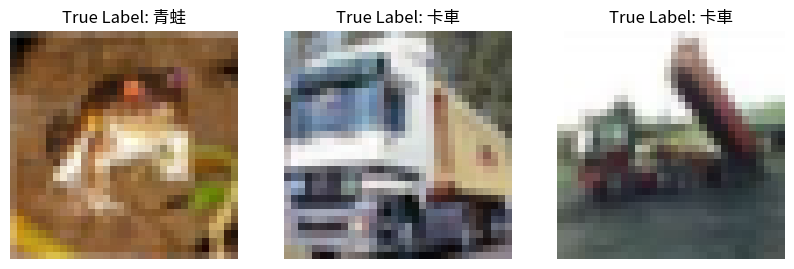

In [9]:
class_name = ['飛機', '汽車', '鳥', '貓', '鹿', '狗', '青蛙', '馬', '船', '卡車']

plt.figure(figsize=(10,4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_train[i])
    plt.title(f"True Label: {class_name[y_train[i].item()]}")
    plt.axis('off')
plt.show()

## 二、建立神經網路模型

In [10]:
model = Sequential()

### 第一層：卷積層 (16 個 Filter，大小為 3x3)
* 圖片尺寸為 32x32
* 彩色圖片 3 通道（RGB）
* 卷積層參數 = (Filter高 × Filter寬 × 前層輸入通道數 + 偏值) × 本層通道數
* Output Shape：(None, 32, 32, 16)

In [11]:
model.add(Conv2D(16, (3,3), padding='same',
        input_shape=(32,32,3),
        activation='relu'))  # (3x3x3+1)x16 = 448

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 第二層：卷積層 (16 個 Filter，大小為 3x3)
* 圖片尺寸為 32x32
* 前一層輸出 16 個通道
* 本層 16 通道
* Output Shape：(None, 32, 32, 16)

In [12]:
model.add(Conv2D(16, (3,3), padding='same',
        activation='relu'))  # (3x3x16+1)x16 = 2320

### 第三層：池化層
* 圖片尺寸為 16x16
* 保留前一層 16 個通道
* Output Shape：(None, 16, 16, 16)
* 池化層沒有需要學習的參數，因此參數數量為 0

In [13]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第四層：卷積層 (32 個 Filter，大小為 3x3)
* 圖片尺寸為 16x16
* 前一層輸出 16 個通道
* 本層 32 通道
* Output Shape：(None, 16, 16, 32)

In [14]:
model.add(Conv2D(32, (3,3), padding='same',
        activation='relu'))  # (3x3x16+1)x32 = 4640

### 第五層：卷積層 (32 個 Filter，大小為 3x3)
* 圖片尺寸為 16x16
* 前一層輸出 32 個通道
* 本層 32 通道
* Output Shape：(None, 16, 16, 32)

In [15]:
model.add(Conv2D(32, (3,3), padding='same',
        activation='relu'))  # (3x3x32+1)x32 = 9248

### 第六層：池化層
* 圖片尺寸為 8x8
* 保留前一層 32 個通道
* Output Shape：(None, 8, 8, 32)

參數數量：0

In [16]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第七層：拉平層
* (8, 8, 32) → 2048
* Output Shape：(None, 2048)

參數數量：0

In [17]:
model.add(Flatten())

### 第八層：全連接層 (10 個神經元)
* 10 個神經元對應 CIFAR-10 的 10 類別
* 每個神經元連接前一層的 2048 個輸入，共有 20480 個權重 + 10 個偏值 = 20490 個參數。
* Output Shape：(None, 10)

In [18]:
model.add(Dense(10, activation='softmax')) # 2048x10+10 = 20490

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,146 (145.10 KB)

 Trainable params: 37,146 (145.10 KB)

 Non-trainable params: 0 (0.00 B)

### 批次訓練 Input Shape 與各層 Output Shape

批次大小（batch_size）設定為 128，每次輸入 128 張 32×32 的 RGB 圖片。

Input Shape：(128, 32, 32, 3)

各層 Output Shape：
1. Conv2D：(128, 32, 32, 16)
2. Conv2D：(128, 32, 32, 16)
3. MaxPooling2D：(128, 16, 16, 16)
4. Conv2D：(128, 16, 16, 32)
5. Conv2D：(128, 16, 16, 32)
6. MaxPooling2D：(128, 8, 8, 32)
7. Flatten：(128, 2048)
8. Dense：(128, 10)

以上為完整批次的形狀，最後一個批次可能不足 128 筆。

## 三、訓練神經網路模型

In [20]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy'])

In [21]:
train_history = model.fit(
    x_train, y_train_oh,
    validation_split=0.2,
    batch_size=128,
    epochs=20,
    verbose=2)

Epoch 1/20
313/313 - 99s - 317ms/step - accuracy: 0.4072 - loss: 1.6472 - val_accuracy: 0.5016 - val_loss: 1.3998
Epoch 2/20
313/313 - 93s - 297ms/step - accuracy: 0.5389 - loss: 1.3004 - val_accuracy: 0.5744 - val_loss: 1.2165
Epoch 3/20
313/313 - 91s - 291ms/step - accuracy: 0.6014 - loss: 1.1341 - val_accuracy: 0.6199 - val_loss: 1.0994
Epoch 4/20
313/313 - 142s - 454ms/step - accuracy: 0.6416 - loss: 1.0305 - val_accuracy: 0.6340 - val_loss: 1.0366
Epoch 5/20
313/313 - 93s - 297ms/step - accuracy: 0.6708 - loss: 0.9540 - val_accuracy: 0.6562 - val_loss: 0.9895
Epoch 6/20
313/313 - 96s - 307ms/step - accuracy: 0.6853 - loss: 0.9025 - val_accuracy: 0.6672 - val_loss: 0.9576
Epoch 7/20
313/313 - 137s - 437ms/step - accuracy: 0.6995 - loss: 0.8648 - val_accuracy: 0.6802 - val_loss: 0.9174
Epoch 8/20
313/313 - 96s - 307ms/step - accuracy: 0.7173 - loss: 0.8167 - val_accuracy: 0.6929 - val_loss: 0.8968
Epoch 9/20
313/313 - 93s - 296ms/step - accuracy: 0.7251 - loss: 0.7906 - val_accuracy

## 四、顯示 loss & accuracy 折線圖

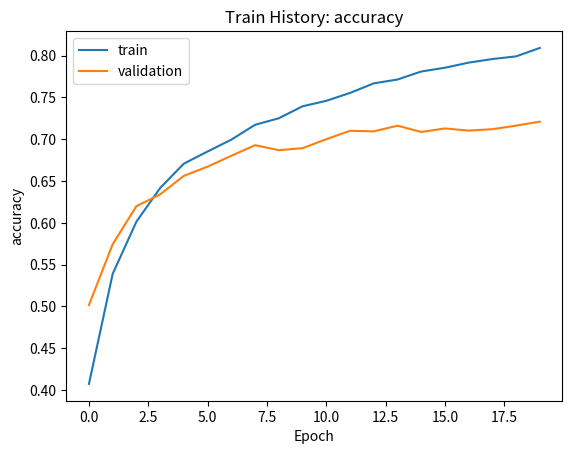

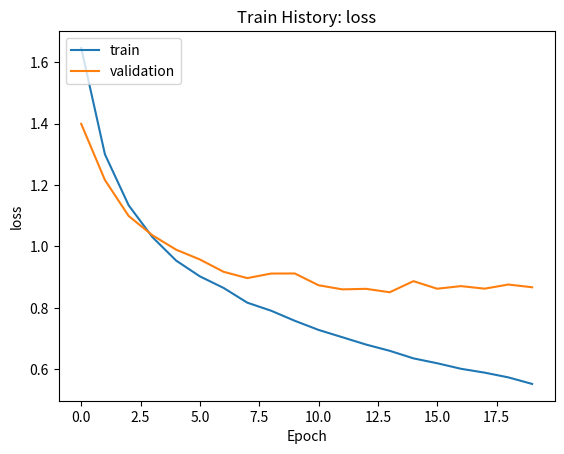

In [22]:
def show_train_history(train_history, train, validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title(f'Train History: {train}')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train', 'validation'], loc='upper left')
  plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy')
show_train_history(train_history, 'loss', 'val_loss')

### Overfitting 分析

從訓練結果可以觀察到，隨著 Epoch 增加，訓練資料的 Accuracy 持續上升，Loss 逐漸下降。

然而，驗證資料的 Accuracy 提升幅度較小，與訓練準確率逐漸產生差距，表示模型有過度擬合（Overfitting）的跡象。

依照要求，這次僅觀察與分析Overfitting 現象，不進行模型改善。

## 五、評估模型準確率

In [23]:
scores = model.evaluate(x_test, y_test_oh)
print(f"accuracy: {scores[1]*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.7097 - loss: 0.9064
accuracy: 70.97%


## 六、預測

In [24]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step


In [25]:
predictions.shape

(10000, 10)

In [26]:
predictions

array([[5.72705234e-04, 6.01085230e-06, 1.44842825e-05, ...,
        5.15824877e-06, 1.13019824e-03, 3.61648745e-06],
       [7.18771899e-03, 6.25308305e-02, 5.28879355e-06, ...,
        2.85901418e-08, 9.29800391e-01, 4.75312612e-04],
       [4.48549777e-01, 4.03351635e-02, 1.58442755e-03, ...,
        1.40366214e-03, 4.87901032e-01, 1.66864283e-02],
       ...,
       [1.31564622e-04, 2.08611610e-07, 2.49419555e-01, ...,
        1.17154997e-02, 5.86463138e-04, 4.91227402e-05],
       [1.62644673e-03, 1.33764252e-01, 8.69057840e-06, ...,
        6.66139458e-05, 2.23433585e-06, 4.64031982e-05],
       [6.89110493e-06, 2.49856268e-04, 2.88046693e-04, ...,
        8.31686378e-01, 3.63397121e-05, 1.53125166e-05]],
      shape=(10000, 10), dtype=float32)

In [27]:
predicted_classes = np.argmax(predictions, axis=1)

## 七、顯示圖片與標籤名稱

In [28]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, true_labels, pred_labels, label_names, idx, num):
  plt.figure(figsize=(6, 7))
  if num > 25: num = 25
  for i in range(num):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[idx + i])

    true_idx = np.squeeze(true_labels[idx + i])
    pred_idx = np.squeeze(pred_labels[idx + i])

    true_name = label_names[true_idx]
    pred_name = label_names[pred_idx]

    plt.title(f'True: {true_name}\nPred: {pred_name}', fontsize=10)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

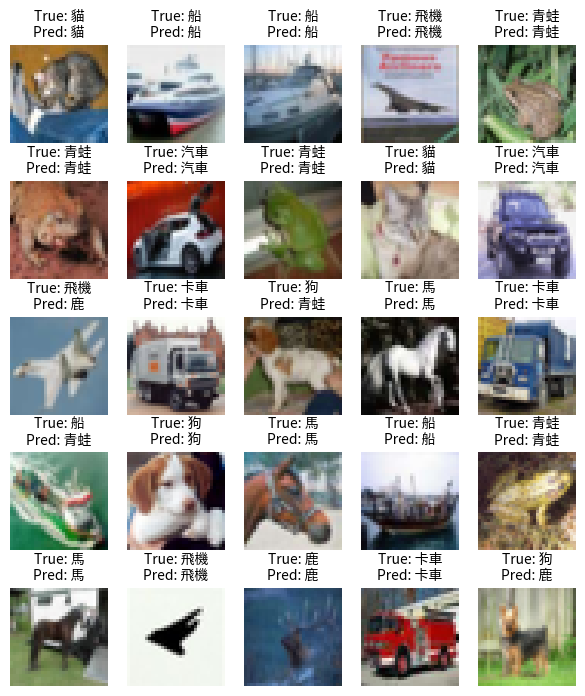

In [29]:
plot_images_labels_prediction(x_test, y_test, predicted_classes, class_name, idx=0, num=25)

## 八、混淆矩陣 (Confusion Matrix)

In [30]:
import pandas as pd

pd.crosstab(np.squeeze(y_test), predicted_classes, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,796,11,32,12,26,9,12,8,52,42
1,36,801,4,3,7,3,13,2,23,108
2,92,6,550,49,125,55,77,26,11,9
3,31,9,85,505,89,133,94,22,13,19
4,20,7,65,49,726,17,66,37,10,3
5,18,3,49,176,75,592,33,35,9,10
6,7,2,50,39,46,9,831,1,8,7
7,28,3,56,44,100,36,11,701,5,16
8,81,30,21,9,5,3,13,6,797,35


## 九、儲存完整模型

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [32]:
%cd /content/drive/MyDrive/Colab Notebooks/

/content/drive/MyDrive/Colab Notebooks


In [33]:
model.save('cnn_cifar10_model_4-1.keras')

## 十、interact_manual

In [34]:
def test(測試編號):
  plt.imshow(x_test[測試編號], cmap='Greys')
  print('神經網路判斷為：', class_name[predicted_classes[測試編號]])
  print('正確答案為：', class_name[np.squeeze(y_test[測試編號])])

interact_manual(test, 測試編號=(0, len(x_test)-1))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>